In [3]:
import ast, json
from pathlib import Path
import pandas as pd

ROOT = Path(r"C:\Users\DELL\derme\data\raw\scin")

with open(ROOT / "metadata.json") as f:
    df = pd.DataFrame(json.load(f))

def to_dict(x):
    if isinstance(x, dict): return x
    if isinstance(x, str):
        try: return ast.literal_eval(x)
        except Exception: return {}
    return {}

df["w"] = df["weighted_skin_condition_label"].apply(to_dict)
df["top_label"] = df["w"].apply(lambda d: max(d, key=d.get) if d else None)
df["top_weight"] = df["w"].apply(lambda d: max(d.values()) if d else 0)
df["is_head"] = df["body_parts_head_or_neck"] == "YES"

df["files"] = df["files"].apply(lambda x: x if isinstance(x, list) else to_dict(x) if False else (ast.literal_eval(x) if isinstance(x, str) else []))
df["n_images"] = df["files"].apply(len)

disk = {p.name: p for p in ROOT.rglob("*.jpg")}
print("jpgs on disk:", len(disk))
print("example:", next(iter(disk.values())) if disk else "NONE FOUND")

all_files = [fn for fl in df["files"] for fn in fl]
missing = [fn for fn in all_files if fn not in disk]
print("files listed in metadata:", len(all_files), "| missing on disk:", len(missing))
print(df["n_images"].value_counts().sort_index())

jpgs on disk: 5033
example: C:\Users\DELL\derme\data\raw\scin\images\00000_0.jpg
files listed in metadata: 10406 | missing on disk: 0
n_images
1    1948
2     797
3    2288
Name: count, dtype: int64


In [4]:
lab = df[df["top_label"].notna()]
unl = df[df["top_label"].isna()]
print("labeled:", len(lab), "| unlabeled:", len(unl))

print("\nTop-label confidence (top_weight) among labeled:")
print(lab["top_weight"].describe().round(2))
print("\nShare with top_weight >= 0.5:", (lab["top_weight"] >= 0.5).mean().round(2))

print("\nShot types (image 1), labeled cases:")
print(lab["image_1_shot_type"].value_counts(dropna=False))
print("\nBody part coverage, labeled cases:")
print(lab.filter(like="body_parts_").eq("YES").sum().sort_values(ascending=False))

labeled: 3061 | unlabeled: 1972

Top-label confidence (top_weight) among labeled:
count    3061.00
mean        0.62
std         0.24
min         0.16
25%         0.41
50%         0.55
75%         0.67
max         1.00
Name: top_weight, dtype: float64

Share with top_weight >= 0.5: 0.73

Shot types (image 1), labeled cases:
image_1_shot_type
CLOSE_UP       1814
AT_AN_ANGLE     730
AT_DISTANCE     517
Name: count, dtype: int64

Body part coverage, labeled cases:
body_parts_leg                   1058
body_parts_arm                   1042
body_parts_torso_front            474
body_parts_head_or_neck           416
body_parts_torso_back             395
body_parts_back_of_hand           333
body_parts_other                  331
body_parts_foot_top_or_side       273
body_parts_buttocks               232
body_parts_palm                   145
body_parts_genitalia_or_groin     144
body_parts_foot_sole               65
dtype: int64


In [5]:
GROUPS = {
    "eczematous_dermatitis": ["Eczema", "Allergic Contact Dermatitis", "Irritant Contact Dermatitis",
                              "CD - Contact dermatitis", "Acute dermatitis, NOS"],
    "urticaria":    ["Urticaria"],
    "insect_bite":  ["Insect Bite"],
    "folliculitis": ["Folliculitis"],
    "psoriasis":    ["Psoriasis"],
    "tinea":        ["Tinea"],
    "acne":         ["Acne"],
}
label_to_group = {lbl: g for g, lbls in GROUPS.items() for lbl in lbls}
df["group"] = df["top_label"].map(label_to_group)

g = df[df["group"].notna()]
summary = pd.DataFrame({
    "cases":        g.groupby("group").size(),
    "conf>=0.5":    g[g["top_weight"] >= 0.5].groupby("group").size(),
    "images":       g.groupby("group")["n_images"].sum(),
    "head/neck":    g[g["is_head"]].groupby("group").size(),
}).fillna(0).astype(int).sort_values("cases", ascending=False)
print(summary)
print("\nTotal grouped cases:", len(g), "of", df["top_label"].notna().sum(), "labeled")

                       cases  conf>=0.5  images  head/neck
group                                                     
eczematous_dermatitis    879        687    1932         90
urticaria                214        182     442         38
insect_bite              185        144     401         17
folliculitis             142        101     306         23
psoriasis                109         65     234         22
tinea                     93         61     211          9
acne                      61         50     123         32

Total grouped cases: 1683 of 3061 labeled


In [15]:
import cv2, numpy as np

sample = g.sample(min(300, len(g)), random_state=0)
rows = []
for _, r in all_cases.iterrows():
    for fn in dict.fromkeys(r["files"]):          # unique filenames only
        if fn not in disk: continue
        rows.append({
            "case_id": r["case_id"], "file": fn,
            "path": str(disk[fn].relative_to(ROOT)),
            "label": r["group"], "top_weight": r["top_weight"],
            "split": r["split"], "fst": r["fst"], "monk": r["monk"],
            "is_head": r["is_head"],
        })
imgs = pd.DataFrame(rows)
print(imgs.describe(percentiles=[.05, .25, .5, .75, .95]).round(1))
imgs.to_csv("quality_sample.csv", index=False)

       top_weight    monk
count      1683.0  1679.0
mean          0.6     2.9
std           0.2     1.5
min           0.2     1.0
5%            0.3     1.0
25%           0.5     2.0
50%           0.6     3.0
75%           0.8     4.0
95%           1.0     6.0
max           1.0    10.0


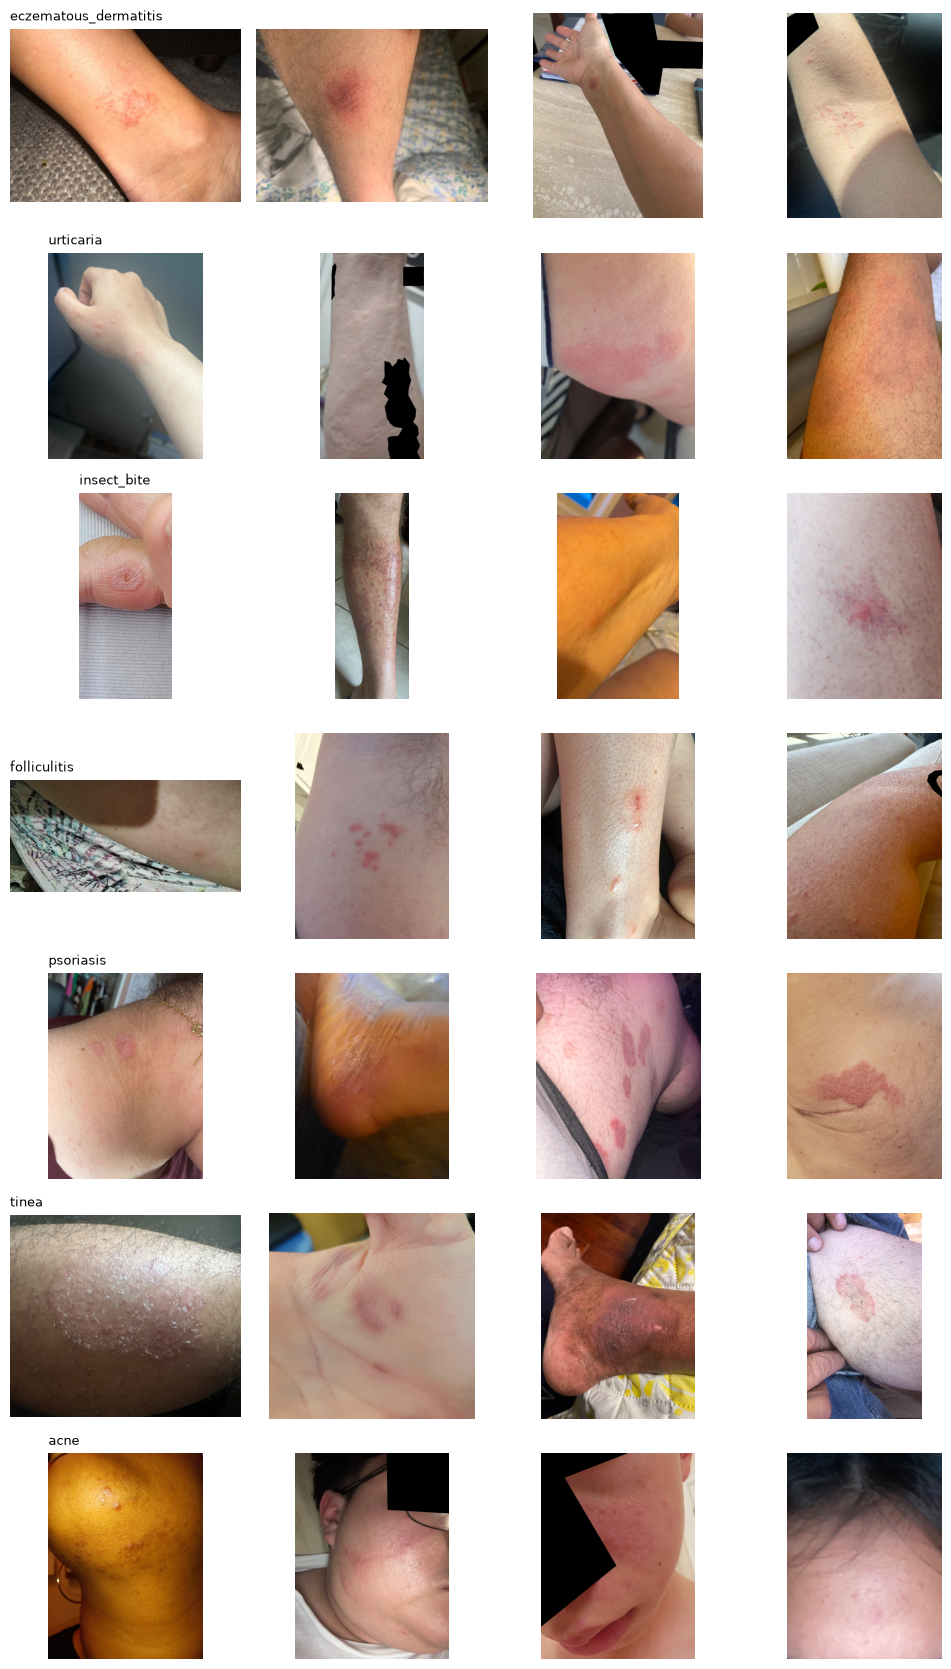

In [7]:
import matplotlib.pyplot as plt
from PIL import Image

classes = summary.index.tolist()
fig, axes = plt.subplots(len(classes), 4, figsize=(10, 2.4 * len(classes)))
for i, c in enumerate(classes):
    pick = g[(g["group"] == c) & (g["n_images"] > 0)].sample(4, random_state=1)
    for j, (_, r) in enumerate(pick.iterrows()):
        ax = axes[i, j]
        ax.imshow(Image.open(disk[r["files"][0]])); ax.axis("off")
        if j == 0: ax.set_title(c, fontsize=9, loc="left")
plt.tight_layout(); plt.show()